<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Ensamble: XGBoost y stacking</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** Tenemos un sistema principal (LR sobre texto, 0.676 de F1 de fake en el test) y un Random Forest sobre rasgos de estilo (0.505). Por separado, el bosque es mucho peor, pero `modelo_arboles.ipynb` encontró que **se equivocan en noticias distintas**: hay 86 que solo acierta el bosque y 173 que solo acierta el texto.

**Para dónde vamos.** Un método de ensamble combina varios modelos en una sola decisión, y mejora cuando los modelos superan al azar y **cometen errores en casos distintos** (Alegre, 2026, láminas 4 y 21). Aquí juntamos las tres familias vistas en clase:

| Familia | Modelo base | Qué ve de la noticia |
|:--|:--|:--|
| Lineal (el principal) | Regresión logística | TF-IDF de palabras y caracteres |
| **Boosting** (nuevo) | XGBoost, ajustado con *grid search* | TF-IDF de palabras y/o rasgos de estilo |
| **Bagging** | Random Forest (`modelo_arboles.ipynb`) | 10 rasgos de estilo |

Encima de ellos va un **meta-modelo** (*stacking*): una regresión logística que recibe las tres probabilidades de *fake* y aprende cuánto confiar en cada una. Lo comparamos con el **soft voting** (promedio simple de las tres probabilidades).

**Reglas del protocolo** (las mismas de todo el proyecto):

1. Toda validación es **CV agrupada por fuente** (`fold_grupo`), también la del *grid search*.
2. El meta-modelo **solo** se entrena con predicciones *out-of-fold* (lámina 22); entrenarlo con predicciones sobre datos que los modelos base ya vieron es fuga (lámina 23).
3. El desempeño del *stacking* se estima con **CV anidada**: el meta-modelo de cada fold se elige y entrena sin ver ese fold.
4. El test se carga **una sola vez**, al final. Como ya se vio en `evaluacion.ipynb`, todo lo de aquí es **sistema aparte**.

Escribe `resultados/xgb_grid.csv`, `resultados/stacking_cv.csv`, `resultados/stacking_test.csv`, `resultados/predicciones_test_stacking.csv`, `resultados/seleccion_stacking.json` y la figura `figuras/6_1_stacking_f1_test.png`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Modelado](#fase-modelado)**
    * [Sección 1: XGBoost con grid search](#seccion-1)
    * [Sección 2: Predicciones out-of-fold de los modelos base](#seccion-2)
    * [Sección 3: ¿Se equivocan en noticias distintas?](#seccion-3)
    * [Sección 4: Meta-modelo con grid search](#seccion-4)
    * [Sección 5: Estimación honesta con CV anidada](#seccion-5)
* **[Metodología CRISP-DM: Evaluación (sistema aparte)](#fase-evaluacion)**
    * [Sección 6: Aplicación única en el test](#seccion-6)
* **[Conclusiones](#conclusiones)**
    * [Sección 7: Resumen y limitaciones](#seccion-7)
    * [Sección 8: Referencias](#seccion-8)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas, constantes, datos preparados y las configuraciones ya elegidas.
>
> **Qué se espera ver:** el entorno `fakedes` con `xgboost` y las 961 noticias de `corpus.parquet`.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import time
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelado y evaluación
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
N_BOOTSTRAP = 1000                                    # los mismos remuestreos que evaluacion.ipynb
N_NUCLEOS = 2                                         # hilos de XGBoost
OFICIALES = {'Baseline BoW + SVM': 0.7217, 'Baseline BETO': 0.7321, '1.er lugar (GDUFS_DM)': 0.7666}

# Rejilla de XGBoost (2 × 2 × 2 = 8 combinaciones por representación)
REJILLA_XGB = {'clasificador__max_depth': [2, 4],              # árboles poco profundos: modelos débiles (lámina 14)
               'clasificador__learning_rate': [0.05, 0.1],     # valores pequeños generalizan mejor (lámina 18)
               'clasificador__n_estimators': [200, 500]}       # con learning rate bajo hacen falta más árboles
REPRESENTACIONES_XGB = ['estilo', 'palabras', 'palabras + estilo']

# Rejilla del meta-modelo
REJILLA_META = {'C': [0.01, 0.1, 1, 10, 100]}
uf.configurar_graficas()
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS)

### 0.3 Datos y configuraciones ya elegidas

In [3]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    config_lr = json.load(f)['elegida']
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_arboles.json'), encoding = 'utf-8') as f:
    config_rf = json.load(f)['elegida']
y = corpus['Category'].values
folds = corpus['fold_grupo'].values
divisiones = PredefinedSplit(test_fold = folds)       # GridSearchCV usa exactamente los 5 folds agrupados por fuente
print(f'Noticias: {len(corpus)}; folds: {sorted(set(folds))}')
print('LR texto:', config_lr)
print('RF estilo:', config_rf)

Noticias: 961; folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
LR texto: {'representacion': 'palabras (1,2) + caracteres (2,5)', 'estructura': 'solo texto', 'sin_medio': True, 'min_df': 20, 'minusculas': True, 'estilo': False, 'k_chi2': None, 'modelo': 'LR', 'valor': 1.0}
RF estilo: {'modelo': 'RF', 'parametros': {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20}}


<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: XGBoost con grid search</span></div>

> **Qué se hace:** buscamos la mejor combinación de profundidad, *learning rate* y número de árboles para tres representaciones distintas, con `GridSearchCV` sobre los 5 folds agrupados por fuente.
>
> **Qué se espera ver:** que XGBoost quede por debajo de la LR sobre texto (en `modelo_arboles.ipynb` los árboles no ganaron a los lineales), pero arriba del Random Forest de estilo.

#### Glosario de la sección
* **Gradient boosting:** árboles entrenados en secuencia; cada uno corrige el residuo de los anteriores (láminas 16 y 17).
* **XGBoost:** implementación de gradient boosting con regularización explícita (lámina 19).
* **Grid search:** probar todas las combinaciones de una rejilla de hiperparámetros y quedarse con la mejor en CV.
* **`PredefinedSplit`:** le dice a `GridSearchCV` que use nuestros folds (`fold_grupo`) en lugar de partir al azar. Sin esto, el grid search mediría el reconocimiento del medio.

**Por qué no usamos los caracteres en XGBoost.** Con las 17,345 columnas de palabras + caracteres, un ajuste tarda entre 12 y 71 segundos (2 núcleos); con las 1,818 de palabras, entre 1 y 5. Además, dejar los caracteres solo en la LR hace que los modelos base vean la noticia de forma distinta, que es lo que busca un ensamble.

**Por qué no usamos *early stopping*.** Necesitaría un conjunto de validación dentro de cada fold. En su lugar, el número de árboles es parte de la rejilla. **Regla de selección** (la misma de `modelo_arboles.ipynb`): entre las combinaciones a menos de un error estándar de la mejor media, la más simple (menor profundidad, luego menos árboles, luego menor *learning rate*).

In [4]:
def representacion_xgb(nombre):
    '''
    Función que crea la representación de entrada de XGBoost

    inputs:
    --------
        nombre (str): 'estilo', 'palabras' o 'palabras + estilo'

    outputs:
    --------
        sklearn.compose.ColumnTransformer: Transformador que recibe el DataFrame preparado
    '''
    if nombre == 'estilo':
        return ColumnTransformer([('estilo', 'passthrough', uf.RASGOS_ESTILO)])
    return uf.crear_representacion('palabras (1,2)', 'solo texto', sin_medio = True, min_df = 20, minusculas = True,
                                   estilo = (nombre == 'palabras + estilo'))

def construir_xgb(representacion, max_depth = 2, learning_rate = 0.05, n_estimators = 200):
    '''
    Función que construye el Pipeline de XGBoost (representación + clasificador)

    inputs:
    --------
        representacion (str): Una de REPRESENTACIONES_XGB
        max_depth (int): Profundidad máxima de cada árbol
        learning_rate (float): Contribución de cada árbol
        n_estimators (int): Número de árboles

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar; se entrena con y numérica (1 = Fake)
    '''
    clasificador = XGBClassifier(max_depth = max_depth, learning_rate = learning_rate, n_estimators = n_estimators,
                                 subsample = 0.8, colsample_bytree = 0.5, tree_method = 'hist',
                                 n_jobs = N_NUCLEOS, random_state = SEMILLA)
    return Pipeline([('representacion', representacion_xgb(representacion)), ('clasificador', clasificador)])

In [5]:
inicio = time.time()
filas = []
for representacion in REPRESENTACIONES_XGB:
    busqueda = GridSearchCV(construir_xgb(representacion), REJILLA_XGB, scoring = 'f1', cv = divisiones, refit = False)
    busqueda.fit(corpus, corpus['y'])                      # y = 1 es Fake, así que 'f1' es la F1 de fake
    r = busqueda.cv_results_
    for i, parametros in enumerate(r['params']):
        por_fold = [r[f'split{k}_test_score'][i] for k in range(5)]
        filas.append({'representacion': representacion,
                      'max_depth': parametros['clasificador__max_depth'],
                      'learning_rate': parametros['clasificador__learning_rate'],
                      'n_estimators': parametros['clasificador__n_estimators'],
                      **{f'fold {k}': por_fold[k] for k in range(5)},
                      'F1_fake_media': np.mean(por_fold), 'F1_fake_sd': np.std(por_fold, ddof = 1)})
grid_xgb = pd.DataFrame(filas)
grid_xgb['F1_fake_se'] = grid_xgb['F1_fake_sd'] / np.sqrt(5)
guardar_csv(grid_xgb, 'xgb_grid')
print(f'{len(grid_xgb)} combinaciones × 5 folds en {(time.time() - inicio) / 60:.1f} min')

24 combinaciones × 5 folds en 2.8 min


**Tabla 1.1.** Mejor combinación de cada representación (F1 de fake en CV agrupada).

In [6]:
grid_xgb.sort_values('F1_fake_media', ascending = False).groupby('representacion').head(1).round(3)

,representacion,max_depth,learning_rate,n_estimators,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd,F1_fake_se
10,palabras,4,0.05,200,0.782,0.629,0.731,0.639,0.722,0.701,0.065,0.029
23,palabras + estilo,4,0.10,500,0.737,0.589,0.733,0.617,0.691,0.674,0.068,0.030
1,estilo,2,0.05,500,0.615,0.528,0.684,0.634,0.726,0.638,0.075,0.033


**Tabla 1.2.** Regla de un error estándar: combinaciones dentro de un SE de la mejor y la elegida.

In [7]:
def regla_un_se(grid):
    '''
    Función que aplica la regla de un error estándar con preferencia por la simplicidad

    inputs:
    --------
        grid (pandas.DataFrame): Una fila por combinación con 'F1_fake_media', 'F1_fake_se' y los hiperparámetros

    outputs:
    --------
        pandas.Series: Fila de la combinación elegida
    '''
    mejor = grid.loc[grid['F1_fake_media'].idxmax()]
    candidatas = grid[grid['F1_fake_media'] >= mejor['F1_fake_media'] - mejor['F1_fake_se']]
    candidatas = candidatas.sort_values(['max_depth', 'n_estimators', 'learning_rate', 'F1_fake_media'],
                                        ascending = [True, True, True, False])
    return candidatas.iloc[0]

elegida_xgb = regla_un_se(grid_xgb)
config_xgb = {'representacion': elegida_xgb['representacion'], 'max_depth': int(elegida_xgb['max_depth']),
              'learning_rate': float(elegida_xgb['learning_rate']), 'n_estimators': int(elegida_xgb['n_estimators'])}
mejor_xgb = grid_xgb.loc[grid_xgb['F1_fake_media'].idxmax()]
umbral_se = mejor_xgb['F1_fake_media'] - mejor_xgb['F1_fake_se']
print(f'Mejor media: {mejor_xgb["F1_fake_media"]:.3f} (SE {mejor_xgb["F1_fake_se"]:.3f}); umbral de la regla: {umbral_se:.3f}')
print(f'Combinaciones dentro de un SE: {int((grid_xgb["F1_fake_media"] >= umbral_se).sum())} de {len(grid_xgb)}')
print('Elegida:', config_xgb)
grid_xgb[grid_xgb['F1_fake_media'] >= umbral_se].sort_values('F1_fake_media', ascending = False).round(3)

Mejor media: 0.701 (SE 0.029); umbral de la regla: 0.671
Combinaciones dentro de un SE: 9 de 24
Elegida: {'representacion': 'palabras', 'max_depth': 2, 'learning_rate': 0.05, 'n_estimators': 200}


,representacion,max_depth,learning_rate,n_estimators,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd,F1_fake_se
10,palabras,4,0.05,200,0.782,0.629,0.731,0.639,0.722,0.701,0.065,0.029
12,palabras,2,0.10,200,0.800,0.642,0.722,0.619,0.718,0.700,0.072,0.032
15,palabras,4,0.10,500,0.776,0.605,0.731,0.638,0.683,0.686,0.069,0.031
14,palabras,4,0.10,200,0.758,0.588,0.726,0.639,0.707,0.684,0.069,0.031
9,palabras,2,0.05,500,0.764,0.651,0.684,0.627,0.690,0.683,0.052,0.023
13,palabras,2,0.10,500,0.782,0.626,0.697,0.606,0.699,0.682,0.070,0.031
11,palabras,4,0.05,500,0.770,0.593,0.702,0.639,0.703,0.681,0.068,0.030
8,palabras,2,0.05,200,0.777,0.561,0.712,0.635,0.701,0.677,0.082,0.037
23,palabras + estilo,4,0.10,500,0.737,0.589,0.733,0.617,0.691,0.674,0.068,0.030


**Qué se observa.**

* **La representación importa más que los hiperparámetros.** La mejor combinación con palabras llega a 0.701; agregar los rasgos de estilo **empeora** (0.674) y el estilo solo da 0.638. Las 9 combinaciones dentro de un error estándar de la mejor (≥ 0.671) usan palabras; 8 de ellas, solo palabras.
* **Elegida por la regla de un SE:** palabras, profundidad 2, *learning rate* 0.05 y 200 árboles: **0.677 ± 0.082**. Es la más simple de las candidatas; la mejor media (profundidad 4) gana apenas 0.024, menos que un SE.
* **Frente a los demás:** XGBoost queda por debajo de la LR sobre texto (0.730) y por encima del Random Forest de estilo (0.608). Sobre los mismos 10 rasgos, XGBoost (0.638) le gana al bosque, igual que la LR sobre rasgos (0.672) en `modelo_arboles.ipynb`.

**El boosting no supera al modelo lineal en texto: con 961 noticias y miles de columnas de TF-IDF, la regresión logística sigue siendo la mejor base.**

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Predicciones out-of-fold de los modelos base</span></div>

> **Qué se hace:** para cada fold entrenamos los tres modelos base con los otros 4 y guardamos su probabilidad de *fake* en el fold que quedó fuera. Esa matriz de 961 × 3 es la entrada del meta-modelo.
>
> **Qué se espera ver:** que con el umbral 0.5 la LR reproduzca su F1 de 0.730 y el Random Forest la de 0.608.

#### Glosario de la sección
* **Predicción *out-of-fold*:** probabilidad que da un modelo que **no** vio esa noticia al entrenar (lámina 22). Con 5 folds, cada noticia recibe exactamente una predicción de cada modelo base.

In [8]:
BASES = ['LR texto', 'XGBoost', 'RF estilo']

def entrenar_base(nombre, datos):
    '''
    Función que entrena un modelo base con las noticias dadas

    inputs:
    --------
        nombre (str): Uno de BASES
        datos (pandas.DataFrame): Noticias preparadas para entrenar

    outputs:
    --------
        sklearn estimator: Modelo entrenado
    '''
    if nombre == 'LR texto':
        return uf.construir_pipeline(config_lr).fit(datos, datos['Category'])
    if nombre == 'XGBoost':
        return construir_xgb(**config_xgb).fit(datos, datos['y'])
    return uf.construir_modelo_estilo(config_rf).fit(datos, datos['Category'])

def probabilidad_fake(modelo, datos):
    '''
    Función que devuelve la probabilidad de fake de un modelo entrenado (con etiquetas de texto o numéricas)

    inputs:
    --------
        modelo (sklearn estimator): Modelo entrenado
        datos (pandas.DataFrame): Noticias a predecir

    outputs:
    --------
        numpy.ndarray: Probabilidad de 'Fake' de cada noticia
    '''
    clases = list(modelo.classes_)
    columna = clases.index('Fake') if 'Fake' in clases else clases.index(1)
    return modelo.predict_proba(datos)[:, columna]

def predicciones_out_of_fold(datos):
    '''
    Función que calcula las probabilidades out-of-fold de los tres modelos base sobre unas noticias

    inputs:
    --------
        datos (pandas.DataFrame): Noticias con la columna 'fold_grupo' (se usan los folds que contenga)

    outputs:
    --------
        pandas.DataFrame: Una columna por modelo base, en el mismo orden que datos
    '''
    oof = pd.DataFrame(0.0, index = datos.index, columns = BASES)
    for k in sorted(datos['fold_grupo'].unique()):
        en_k = datos['fold_grupo'] == k
        for nombre in BASES:
            modelo = entrenar_base(nombre, datos[~en_k])
            oof.loc[en_k, nombre] = probabilidad_fake(modelo, datos[en_k])
    return oof

def clases(prob, umbral = 0.5):
    '''
    Función que convierte probabilidades de fake en clases

    inputs:
    --------
        prob (array-like): Probabilidades de 'Fake'
        umbral (float): Valor de corte

    outputs:
    --------
        numpy.ndarray: 'Fake' si prob >= umbral; 'True' en otro caso
    '''
    return np.where(np.asarray(prob) >= umbral, 'Fake', 'True')

inicio = time.time()
Z = predicciones_out_of_fold(corpus)
print(f'Listo en {time.time() - inicio:.0f} s')

Listo en 22 s


**Tabla 2.1.** F1 de fake de cada modelo base por fold, con sus probabilidades out-of-fold y el umbral 0.5.

In [9]:
f1_bases = pd.DataFrame({n: [uf.f1_fake(y[folds == k], clases(Z.loc[folds == k, n])) for k in range(5)] for n in BASES})
f1_bases.loc['media'] = f1_bases.mean()
f1_bases.loc['sd'] = f1_bases.iloc[:5].std()
f1_bases.round(4)

,LR texto,XGBoost,RF estilo
0,0.7848,0.7769,0.7160
1,0.8541,0.5605,0.3239
2,0.6345,0.7125,0.6839
3,0.6375,0.6353,0.5904
4,0.7381,0.7011,0.7273
media,0.7298,0.6773,0.6083
sd,0.0951,0.0823,0.1678


**Qué se observa.** Con el umbral 0.5, la LR reproduce su F1 de 0.7298 y el bosque la de 0.6083; XGBoost da 0.6773, la misma de la Sección 1. El fold 1 es el mejor de la LR (0.854) y el peor de los árboles (XGBoost 0.561, bosque 0.324): en ese fold, cualquier combinación que les dé peso a los árboles va a perder.

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: ¿Se equivocan en noticias distintas?</span></div>

> **Qué se hace:** medimos qué tan parecidas son las probabilidades de los tres modelos y en cuántas noticias falla cada uno solo.
>
> **Qué se espera ver:** probabilidades poco correlacionadas entre el bosque de estilo y los modelos de texto; si los tres fallaran en lo mismo, ningún ensamble podría mejorar (lámina 4).

#### Glosario de la sección
* **Oráculo:** un selector imaginario que, para cada noticia, elige el modelo que acierta. Su exactitud es la cota máxima que podría alcanzar cualquier combinación; no es alcanzable.

**Tabla 3.1.** Correlación de Spearman entre las probabilidades out-of-fold.

In [10]:
Z.corr(method = 'spearman').round(3)

,LR texto,XGBoost,RF estilo
LR texto,1.000,0.801,0.678
XGBoost,0.801,1.000,0.689
RF estilo,0.678,0.689,1.000


**Tabla 3.2.** Aciertos y errores de los modelos base (umbral 0.5) sobre las 961 noticias.

In [11]:
aciertos = pd.DataFrame({n: clases(Z[n]) == y for n in BASES})
n_aciertos = aciertos.sum(axis = 1)
filas = [('aciertan los 3', int((n_aciertos == 3).sum()))]
for n in BASES:
    otros = [m for m in BASES if m != n]
    filas.append((f'solo acierta {n}', int((aciertos[n] & ~aciertos[otros].any(axis = 1)).sum())))
    filas.append((f'solo falla {n}', int((~aciertos[n] & aciertos[otros].all(axis = 1)).sum())))
filas.append(('fallan los 3', int((n_aciertos == 0).sum())))
filas.append(('exactitud del oráculo (al menos uno acierta)', round(float((n_aciertos > 0).mean()), 3)))
filas.append(('exactitud de la mejor base sola', round(float(aciertos.mean().max()), 3)))
pd.DataFrame(filas, columns = ['caso', 'noticias'])

,caso,noticias
0,aciertan los 3,500.000
1,solo acierta LR texto,67.000
2,solo falla LR texto,40.000
3,solo acierta XGBoost,29.000
4,solo falla XGBoost,52.000
5,solo acierta RF estilo,39.000
6,solo falla RF estilo,109.000
7,fallan los 3,125.000
8,exactitud del oráculo (al menos uno acierta),0.870
9,exactitud de la mejor base sola,0.758


**Qué se observa.**

* **La LR y XGBoost se parecen mucho** (Spearman 0.801): los dos leen palabras del texto. El bosque de estilo es el más distinto (0.678 y 0.689).
* **Hay potencial, pero con un piso duro.** El oráculo llegaría a 0.870 de exactitud contra 0.758 de la mejor base: hay 135 noticias (67 + 29 + 39) que acierta un solo modelo. Pero **125 noticias (13 %) las fallan los tres**, y ningún ensamble puede rescatarlas.
* **El bosque falla solo en 109 noticias** que los otros dos aciertan: es la base más débil, y si el meta-modelo le da peso, arrastra esos errores.

**Se cumple a medias la condición de la lámina 4: los errores no son idénticos, pero la LR y XGBoost se equivocan en casos parecidos, y la base más distinta es también la más débil.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Meta-modelo con grid search</span></div>

> **Qué se hace:** entrenamos una regresión logística sobre las tres probabilidades out-of-fold y elegimos su regularización `C` con `GridSearchCV` en los mismos folds. También calculamos el soft voting (promedio simple).
>
> **Qué se espera ver:** pesos positivos para los tres modelos, más grande el de la LR de texto; y una F1 un poco arriba de la mejor base.

#### Glosario de la sección
* **Meta-modelo (nivel 2):** modelo cuya entrada son las predicciones de los modelos base y cuya salida es la decisión final (lámina 21).
* **`C`:** inverso de la regularización. Con `C` chico, los pesos se encogen hacia cero; con `C` grande, el meta-modelo confía más en los datos.
* **Soft voting:** promediar las probabilidades sin aprender pesos (lámina 20). Es la referencia: si el meta-modelo no le gana, aprender pesos no vale la pena.

**Regla de selección de `C`:** la mayor F1 de fake media; en empate, la `C` más chica.

In [12]:
def ajustar_meta(Z_entrenamiento, y_numerica, folds_entrenamiento):
    '''
    Función que elige C por grid search con los folds dados y entrena el meta-modelo

    inputs:
    --------
        Z_entrenamiento (pandas.DataFrame): Probabilidades out-of-fold de los modelos base
        y_numerica (array-like): 1 = Fake, 0 = True
        folds_entrenamiento (array-like): Fold de cada noticia

    outputs:
    --------
        tuple: (meta-modelo entrenado, C elegida, tabla del grid search)
    '''
    busqueda = GridSearchCV(LogisticRegression(class_weight = 'balanced', max_iter = 5000), REJILLA_META,
                            scoring = 'f1', cv = PredefinedSplit(test_fold = folds_entrenamiento), refit = False)
    busqueda.fit(Z_entrenamiento.values, y_numerica)
    tabla = pd.DataFrame({'C': [p['C'] for p in busqueda.cv_results_['params']],
                          'F1_fake_media': busqueda.cv_results_['mean_test_score']})
    mejores = tabla[np.isclose(tabla['F1_fake_media'], tabla['F1_fake_media'].max())]
    c_elegida = float(mejores['C'].min())
    meta = LogisticRegression(C = c_elegida, class_weight = 'balanced', max_iter = 5000).fit(Z_entrenamiento.values, y_numerica)
    return meta, c_elegida, tabla

meta, c_meta, grid_meta = ajustar_meta(Z, corpus['y'].values, folds)
print(f'C elegida: {c_meta}')
grid_meta.round(4)

C elegida: 100.0


,C,F1_fake_media
0,0.01,0.7170
1,0.10,0.7186
2,1.00,0.7232
3,10.00,0.7218
4,100.00,0.7251


**Tabla 4.1.** Pesos que aprende el meta-modelo (entrenado con las 961 predicciones out-of-fold). Como las tres entradas están en la misma escala (probabilidades de 0 a 1), los pesos se pueden comparar entre sí.

In [13]:
pesos = pd.DataFrame({'peso': list(meta.coef_[0]) + [meta.intercept_[0]]}, index = BASES + ['intercepto'])
pesos['peso relativo (%)'] = list((100 * meta.coef_[0] / np.abs(meta.coef_[0]).sum()).round(1)) + ['—']
pesos.round(3)

,peso,peso relativo (%)
LR texto,6.352,68.3
XGBoost,2.023,21.7
RF estilo,-0.931,-10.0
intercepto,-3.395,—


**Qué se observa.**

* **El grid search de `C` es plano:** de 0.717 a 0.725. Se elige `C = 100`, la de mayor media.
* **Pesos:** la LR se lleva el 68 % (6.35), XGBoost el 22 % (2.02) y el bosque recibe un peso **negativo** (−0.93). Una vez que el meta-modelo conoce la LR y XGBoost, la probabilidad del bosque ya no aporta, y su peso queda absorbiendo ruido.
* **Primera alerta:** aun en esta estimación optimista (sin anidar), la F1 del meta-modelo (0.725) no supera a la LR sola (0.730).

**El meta-modelo hace lo que la lámina 21 dice que debe hacer, que es aprender cuánto confiar en cada base, y concluye que hay que confiar casi solo en la LR.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Estimación honesta con CV anidada</span></div>

> **Qué se hace:** para cada fold externo, repetimos **todo** el stacking sin verlo: predicciones out-of-fold de los modelos base con CV interna sobre los otros 4 folds, *grid search* de `C` con esas predicciones y entrenamiento del meta-modelo. Luego lo aplicamos al fold externo.
>
> **Qué se espera ver:** que el stacking quede cerca del soft voting; con 961 noticias, una ganancia de más de 0.02 sobre la mejor base sería sorprendente.

#### Glosario de la sección
* **Por qué hace falta la CV anidada:** en la Sección 4, `C` se eligió con las predicciones de los 5 folds. Si evaluamos en esos mismos folds, el meta-modelo ya "vio" las respuestas. Aquí el fold externo nunca participa ni en el meta-modelo ni en la elección de `C`.
* **Qué no se anida:** los hiperparámetros de XGBoost (Sección 1), igual que los de la LR y el bosque en sus notebooks. Es una limitación compartida por todos los sistemas.

In [14]:
inicio = time.time()
filas = []
for k in range(5):
    afuera = folds == k
    dentro = corpus[~afuera]
    Z_dentro = predicciones_out_of_fold(dentro)                         # CV interna: 4 folds
    meta_k, c_k, _ = ajustar_meta(Z_dentro, dentro['y'].values, dentro['fold_grupo'].values)
    Z_afuera = Z.loc[afuera, BASES]                                     # modelos base entrenados con los 4 folds de dentro
    prob_stack = meta_k.predict_proba(Z_afuera.values)[:, 1]
    fila = {'fold': k, 'C elegida': c_k}
    for n in BASES:
        fila[n] = uf.f1_fake(y[afuera], clases(Z_afuera[n]))
    fila['soft voting'] = uf.f1_fake(y[afuera], clases(Z_afuera.mean(axis = 1)))
    fila['stacking'] = uf.f1_fake(y[afuera], clases(prob_stack))
    fila.update({f'peso {n}': w for n, w in zip(BASES, meta_k.coef_[0])})
    filas.append(fila)
cv_stack = pd.DataFrame(filas)
guardar_csv(cv_stack, 'stacking_cv')
print(f'CV anidada en {(time.time() - inicio) / 60:.1f} min')

CV anidada en 1.3 min


**Tabla 5.1.** F1 de fake en cada fold externo (CV anidada).

In [15]:
sistemas_cv = BASES + ['soft voting', 'stacking']
tabla_cv = cv_stack[['fold', 'C elegida'] + sistemas_cv].copy()
resumen_cv = pd.DataFrame([{'fold': 'media', **cv_stack[sistemas_cv].mean().to_dict()},
                           {'fold': 'sd', **cv_stack[sistemas_cv].std().to_dict()}])
pd.concat([tabla_cv, resumen_cv], ignore_index = True).round(4)

,fold,C elegida,LR texto,XGBoost,RF estilo,soft voting,stacking
0,0,100.00,0.7848,0.7769,0.7160,0.7886,0.8263
1,1,10.00,0.8541,0.5605,0.3239,0.6038,0.5644
2,2,10.00,0.6345,0.7125,0.6839,0.7320,0.6795
3,3,0.01,0.6375,0.6353,0.5904,0.6429,0.6328
4,4,0.10,0.7381,0.7011,0.7273,0.7251,0.7182
5,media,NaN,0.7298,0.6773,0.6083,0.6985,0.6842
6,sd,NaN,0.0951,0.0823,0.1678,0.0742,0.0979


**Tabla 5.2.** Diferencia pareada por fold frente a la LR de texto (el principal).

In [16]:
filas = []
for s in ['XGBoost', 'RF estilo', 'soft voting', 'stacking']:
    d = cv_stack[s] - cv_stack['LR texto']
    filas.append({'sistema': s, 'diferencia media': d.mean(), 'sd': d.std(), 'folds en que gana': int((d > 0).sum())})
pd.DataFrame(filas).round(4)

,sistema,diferencia media,sd,folds en que gana
0,XGBoost,-0.0525,0.1413,1
1,RF estilo,-0.1215,0.2328,1
2,soft voting,-0.0313,0.1299,3
3,stacking,-0.0456,0.1393,2


**Tabla 5.3.** Pesos del meta-modelo en cada fold externo (estabilidad).

In [17]:
cv_stack[['fold', 'C elegida'] + [f'peso {n}' for n in BASES]].round(3)

,fold,C elegida,peso LR texto,peso XGBoost,peso RF estilo
0,0,100.00,7.402,-0.621,1.714
1,1,10.00,1.126,2.407,3.117
2,2,10.00,8.266,-0.154,0.037
3,3,0.01,0.330,0.492,0.218
4,4,0.10,1.485,1.699,0.415


**Qué se observa.**

* **El stacking no le gana a la LR sola:** 0.684 ± 0.098 contra 0.730 ± 0.095. Pierde en 3 de 5 folds (diferencia media −0.046 ± 0.139). El soft voting queda en 0.698 y también pierde en promedio (−0.031): gana en 3 de 5 folds, pero en el fold 1 pierde 0.25.
* **El fold 1 lo explica casi todo.** La LR saca 0.854 y los árboles se hunden; el stacking cae a 0.564 y el soft voting a 0.604. En el fold 0 pasa lo contrario: el stacking sube a 0.826 (+0.042).
* **El meta-modelo es inestable.** La `C` elegida va de 0.01 a 100, el peso de XGBoost cambia de signo (−0.62 a 2.41) y el del bosque va de 0.04 a 3.12. Con 4 folds de entrenamiento no hay datos suficientes para aprender pesos confiables.

**Con la estimación honesta, ni el stacking ni el soft voting mitigan los errores: combinar con modelos más débiles y correlacionados le resta a la LR más de lo que le suma.**

<a id="fase-evaluacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Evaluación (sistema aparte)</span></div>

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Aplicación única en el test</span></div>

> **Qué se hace:** entrenamos los tres modelos base con las 961 noticias, calculamos sus probabilidades para el test y las combinamos con el meta-modelo de la Sección 4 (entrenado con las predicciones out-of-fold). Se corre **una sola vez**.
>
> **Qué se espera ver:** que el orden entre sistemas se parezca al de la CV anidada; con 572 noticias, diferencias menores de ±0.04 no serán concluyentes.

Los sistemas que se evalúan quedaron fijados antes de cargar el test: XGBoost solo, soft voting y stacking. El principal y el umbral 0.34 (`umbral.ipynb`) se repiten como referencia. Usamos los **mismos 1,000 remuestreos bootstrap** de `evaluacion.ipynb`, así que las diferencias se miden de forma pareada.

In [18]:
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_stacking.json'), 'w', encoding = 'utf-8') as f:
    json.dump({'bases': BASES, 'config_xgb': config_xgb, 'C_meta': c_meta,
               'pesos_meta': dict(zip(BASES, [float(w) for w in meta.coef_[0]])), 'intercepto_meta': float(meta.intercept_[0]),
               'cv_anidada': {s: float(cv_stack[s].mean()) for s in sistemas_cv}}, f, ensure_ascii = False, indent = 1)

test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'))
y_test = test['Category'].values
Z_test = pd.DataFrame({n: probabilidad_fake(entrenar_base(n, corpus), test) for n in BASES})
prob_stack_test = meta.predict_proba(Z_test.values)[:, 1]
previas = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test_umbral.csv')).set_index('id_unico').loc[test['id_unico']]

predicciones = {'LR texto (principal)': clases(Z_test['LR texto']),
                'LR texto, umbral 0.34': previas['LR texto, umbral 0.34'].values,
                'XGBoost': clases(Z_test['XGBoost']),
                'RF estilo': clases(Z_test['RF estilo']),
                'Soft voting (3 bases)': clases(Z_test.mean(axis = 1)),
                'Stacking (meta-modelo LR)': clases(prob_stack_test)}
print(f'Principal igual a evaluacion.ipynb: {100 * np.mean(predicciones["LR texto (principal)"] == previas["LR texto (principal)"].values):.1f} %')
guardar_csv(pd.DataFrame({'id_unico': test['id_unico'].values, 'Category': y_test,
                          **{f'prob {n}': Z_test[n].round(4).values for n in BASES},
                          'prob stacking': prob_stack_test.round(4), **predicciones}), 'predicciones_test_stacking')

Principal igual a evaluacion.ipynb: 100.0 %


'resultados/predicciones_test_stacking.csv'

**Tabla 6.1.** Métricas en el test. El intervalo es bootstrap del 95 %.

In [19]:
rng = np.random.default_rng(SEMILLA)
indices_boot = rng.integers(0, len(test), size = (N_BOOTSTRAP, len(test)))
boot = {n: np.array([uf.f1_fake(y_test[i], p[i]) for i in indices_boot]) for n, p in predicciones.items()}
cv_umbral = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'umbral_anidado.csv'))['F1 fake con umbral interno'].mean()
cv_de = {'LR texto (principal)': cv_stack['LR texto'].mean(), 'LR texto, umbral 0.34': cv_umbral,'XGBoost': cv_stack['XGBoost'].mean(),
         'RF estilo': cv_stack['RF estilo'].mean(), 'Soft voting (3 bases)': cv_stack['soft voting'].mean(), 'Stacking (meta-modelo LR)': cv_stack['stacking'].mean()}
filas = []
for nombre, pred in predicciones.items():
    m = uf.metricas(y_test, pred)
    filas.append({'sistema': nombre, **{c: round(v, 4) for c, v in m.items()},
                  'IC95 F1_fake': f'[{np.percentile(boot[nombre], 2.5):.3f}, {np.percentile(boot[nombre], 97.5):.3f}]',
                  'F1_fake en CV': round(cv_de[nombre], 3), 'predichas Fake': int((pred == 'Fake').sum())})
resultados = pd.DataFrame(filas).set_index('sistema')
guardar_csv(resultados, 'stacking_test', index = True)
resultados

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV,predichas Fake
sistema,,,,,,,,,
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730,193
"LR texto, umbral 0.34",0.7346,0.6882,0.7114,0.7133,0.6837,0.7937,"[0.696, 0.771]",0.744,332
XGBoost,0.6424,0.7273,0.6848,0.6906,0.7608,0.5559,"[0.592, 0.691]",0.677,209
RF estilo,0.5054,0.6637,0.5846,0.5997,0.6610,0.4091,"[0.446, 0.560]",0.608,177
Soft voting (3 bases),0.6446,0.7394,0.6920,0.6993,0.7879,0.5455,"[0.595, 0.693]",0.698,198
Stacking (meta-modelo LR),0.6960,0.7440,0.7200,0.7220,0.7679,0.6364,"[0.652, 0.741]",0.684,237


**Tabla 6.2.** Comparaciones pareadas en el test: bootstrap y McNemar exacta.

In [20]:
def comparar(a, b):
    '''
    Función que compara dos sistemas en el test con bootstrap pareado y McNemar exacta

    inputs:
    --------
        a (str): Sistema que se compara
        b (str): Sistema de referencia

    outputs:
    --------
        dict: Diferencia de F1 de fake, IC95 pareado, remuestreos en que gana a y McNemar
    '''
    dif = boot[a] - boot[b]
    ok_a, ok_b = predicciones[a] == y_test, predicciones[b] == y_test
    solo_a, solo_b = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return {'comparación': f'{a} − {b}', 'diferencia F1 fake': f'{uf.f1_fake(y_test, predicciones[a]) - uf.f1_fake(y_test, predicciones[b]):+.3f}',
            'IC95 pareado': f'[{np.percentile(dif, 2.5):+.3f}, {np.percentile(dif, 97.5):+.3f}]',
            'remuestreos en que gana': f'{int((dif > 0).sum())} de {N_BOOTSTRAP}',
            'McNemar (solo a / solo b)': f'{solo_a} / {solo_b}', 'p McNemar': round(stats.binomtest(solo_a, solo_a + solo_b, 0.5).pvalue, 3)}

pd.DataFrame([comparar('Stacking (meta-modelo LR)', 'LR texto (principal)'),
              comparar('Stacking (meta-modelo LR)', 'Soft voting (3 bases)'),
              comparar('Stacking (meta-modelo LR)', 'LR texto, umbral 0.34'),
              comparar('XGBoost', 'LR texto (principal)')])

,comparación,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,Stacking (meta-modelo LR) − LR texto (principal),+0.020,"[-0.009, +0.049]",923 de 1000,22 / 26,0.665
1,Stacking (meta-modelo LR) − Soft voting (3 bases),+0.051,"[+0.019, +0.083]",1000 de 1000,33 / 20,0.098
2,"Stacking (meta-modelo LR) − LR texto, umbral 0.34",-0.039,"[-0.075, -0.004]",17 de 1000,50 / 45,0.682
3,XGBoost − LR texto (principal),-0.034,"[-0.074, +0.009]",68 de 1000,31 / 53,0.021


**Figura 6.1.** F1 de fake en el test con intervalo bootstrap del 95 %; las líneas verticales son los resultados oficiales en el mismo test.

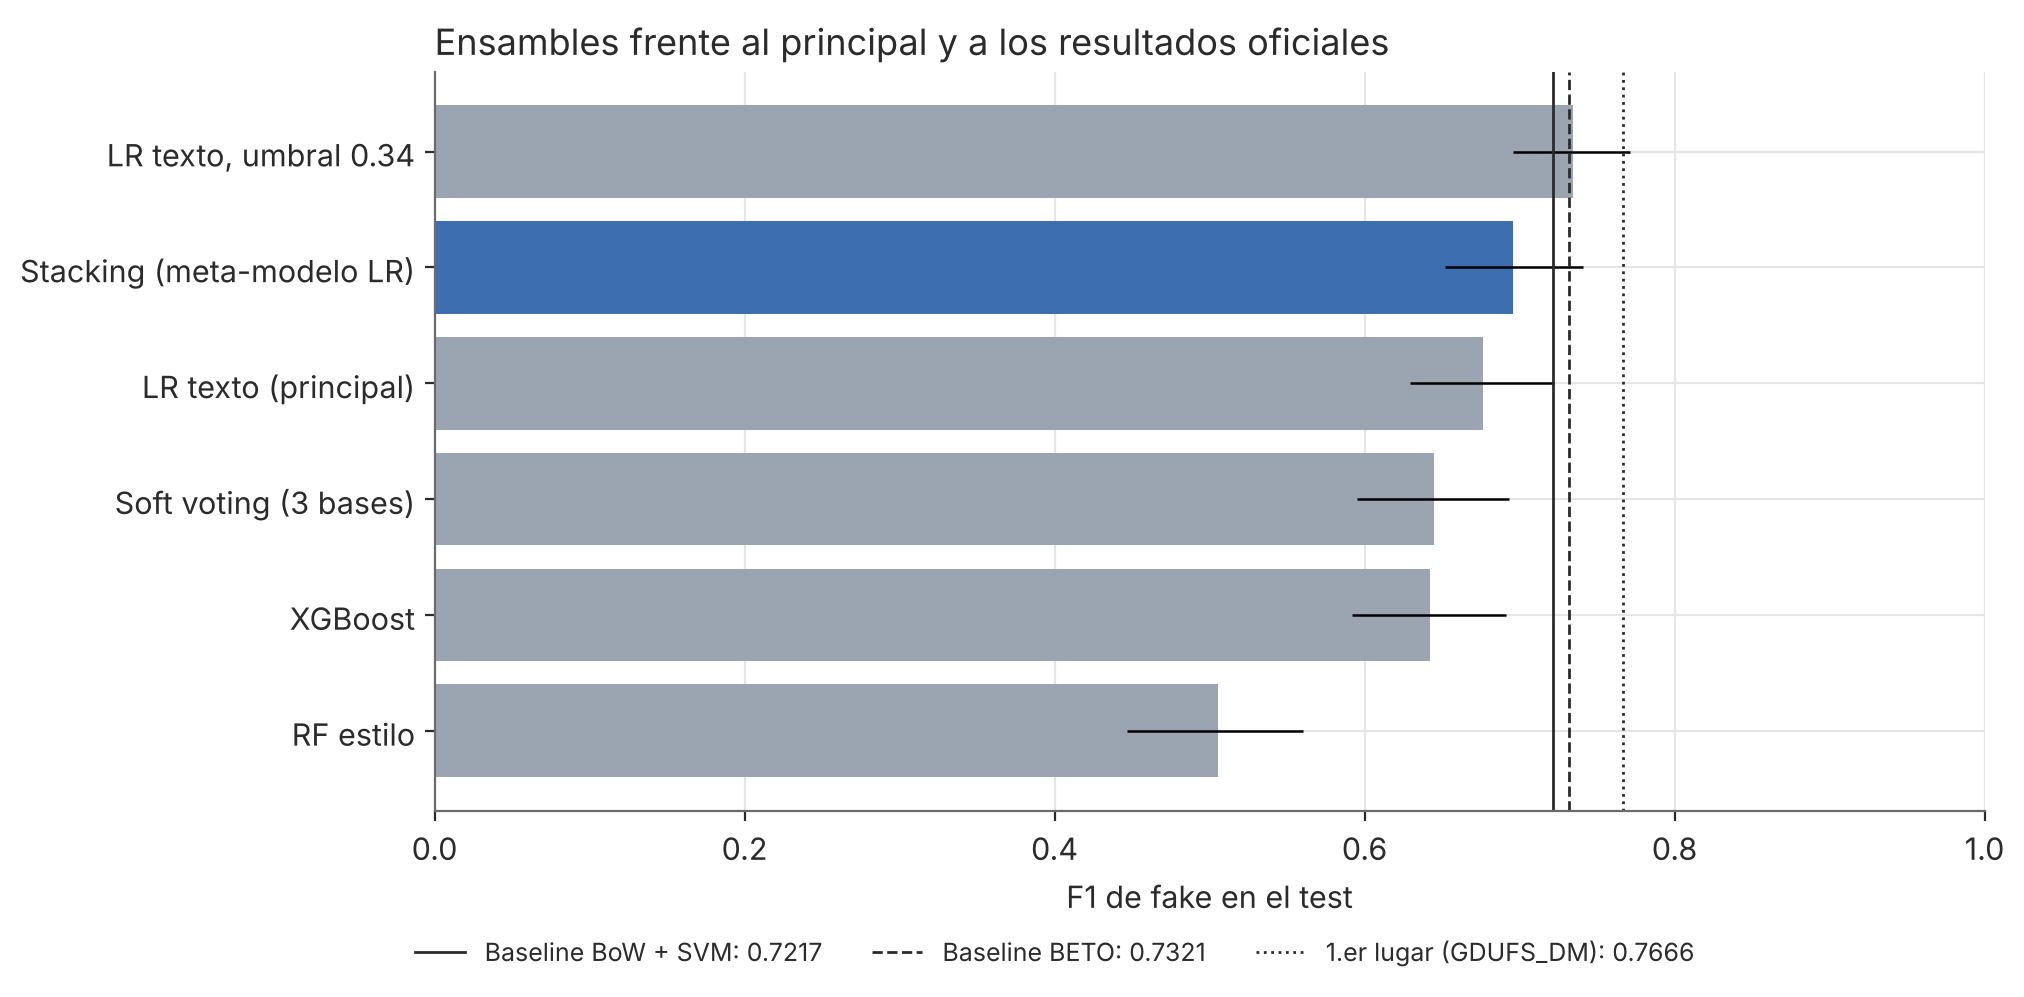

In [21]:
orden = resultados['F1_fake'].sort_values().index
fig, ax = plt.subplots(figsize = (10, 4.8))
error = np.array([[resultados.loc[n, 'F1_fake'] - np.percentile(boot[n], 2.5) for n in orden],
                  [np.percentile(boot[n], 97.5) - resultados.loc[n, 'F1_fake'] for n in orden]])
colores = ['#3D6FB0' if 'Stacking' in n else '#9aa5b1' for n in orden]
ax.barh(orden, resultados.loc[orden, 'F1_fake'], xerr = error, color = colores, error_kw = {'lw': 0.9})
for (etiqueta, valor), estilo in zip(OFICIALES.items(), ['-', '--', ':']):
    ax.axvline(valor, color = TINTA, linestyle = estilo, linewidth = 1, label = f'{etiqueta}: {valor:.4f}')
ax.set_xlim(0, 1)
ax.set_xlabel('F1 de fake en el test')
ax.set_title('Ensambles frente al principal y a los resultados oficiales')
ax.legend(loc = 'upper center', bbox_to_anchor = (0.4, -0.14), ncol = 3, fontsize = 9)
guardar(fig, '6_1_stacking_f1_test')
plt.show()

**Tabla 6.3.** Falsas detectadas en el test por cuartil de longitud (el punto débil del principal).

In [22]:
cuartil = pd.qcut(test['est_log_palabras'], 4, labels = ['Q1 (más cortas)', 'Q2', 'Q3', 'Q4 (más largas)'])
es_falsa = y_test == 'Fake'
pd.DataFrame({n: [100 * np.mean(p[es_falsa & (cuartil == q).values] == 'Fake') for q in cuartil.cat.categories] for n, p in predicciones.items()},
             index = cuartil.cat.categories).round(1)

,LR texto (principal),"LR texto, umbral 0.34",XGBoost,RF estilo,Soft voting (3 bases),Stacking (meta-modelo LR)
Q1 (más cortas),78.2,90.9,78.2,57.3,78.2,84.5
Q2,54.3,75.3,61.7,51.9,58.0,63.0
Q3,38.7,72.6,35.5,17.7,33.9,46.8
Q4 (más largas),24.2,63.6,3.0,3.0,6.1,27.3


**Tabla 6.4.** Diagnóstico: ¿el stacking combina modelos o solo mueve el umbral de la LR? Comparamos con la LR sola cortada en el umbral que marca **el mismo número de falsas** que el stacking. Es un diagnóstico descriptivo sobre el test, **no** un sistema que se pueda elegir así.

In [23]:
n_fake_stack = int((predicciones['Stacking (meta-modelo LR)'] == 'Fake').sum())
umbral_equivalente = np.sort(Z_test['LR texto'].values)[::-1][n_fake_stack - 1]
pred_lr_equivalente = clases(Z_test['LR texto'], umbral_equivalente)
pd.DataFrame([
    ('Spearman: probabilidad del stacking frente a la de la LR', round(stats.spearmanr(prob_stack_test, Z_test['LR texto']).correlation, 3)),
    ('Spearman: probabilidad del stacking frente a la de XGBoost', round(stats.spearmanr(prob_stack_test, Z_test['XGBoost']).correlation, 3)),
    ('Spearman: probabilidad del stacking frente a la del RF', round(stats.spearmanr(prob_stack_test, Z_test['RF estilo']).correlation, 3)),
    (f'Umbral de la LR que marca {n_fake_stack} falsas, como el stacking', round(float(umbral_equivalente), 3)),
    ('F1 de fake de la LR con ese umbral', round(uf.f1_fake(y_test, pred_lr_equivalente), 4)),
    ('F1 de fake del stacking', round(uf.f1_fake(y_test, predicciones['Stacking (meta-modelo LR)']), 4)),
    ('Noticias en que coinciden (%)', round(100 * float(np.mean(pred_lr_equivalente == predicciones['Stacking (meta-modelo LR)'])), 1)),
], columns = ['diagnóstico', 'valor'])

,diagnóstico,valor
0,Spearman: probabilidad del stacking frente a l...,0.9840
1,Spearman: probabilidad del stacking frente a l...,0.9170
2,Spearman: probabilidad del stacking frente a l...,0.6530
3,"Umbral de la LR que marca 237 falsas, como el ...",0.4440
4,F1 de fake de la LR con ese umbral,0.7113
5,F1 de fake del stacking,0.6960
6,Noticias en que coinciden (%),94.4000


**Qué se observa.**

* **Verificación.** El principal reentrenado da las mismas 572 predicciones que `evaluacion.ipynb`.
* **Resultados** (Tabla 6.1). Stacking **0.696** (IC95 [0.652, 0.741]), contra 0.676 del principal y 0.735 del umbral 0.34. XGBoost solo da 0.642 y el soft voting 0.645.
* **Frente al principal** (Tabla 6.2). +0.020, IC95 pareado [−0.009, +0.049], que incluye el 0; McNemar 22 contra 26 (p = 0.665). **Sin diferencia demostrada.**
* **Frente al soft voting.** +0.051 [+0.019, +0.083]: aprender pesos sí es mejor que promediar, porque el promedio le da un tercio del voto al bosque.
* **Frente al umbral 0.34.** −0.039 [−0.075, −0.004]: el umbral solo es mejor que el stacking.
* **XGBoost solo** acierta menos noticias que el principal (McNemar 31 contra 53, p = 0.021).
* **Falsas largas** (Tabla 6.3). XGBoost y el bosque detectan solo el 3 % del cuartil más largo: **tienen el mismo sesgo de longitud que la LR, más fuerte**. No complementan justo donde la LR falla. El stacking llega al 27 % y el umbral al 64 %.
* **¿Combina o mueve el umbral?** (Tabla 6.4). La probabilidad del stacking ordena las noticias casi igual que la LR (Spearman 0.984). Si a la LR sola se le pone el umbral que marca las mismas 237 falsas (0.444), obtiene **0.711, más que el stacking**, y coincide con él en el 94.4 % de las noticias. La mejora frente al principal viene del intercepto del meta-modelo, que baja el corte, no de combinar modelos.

**En el test, el stacking es básicamente la LR con un umbral un poco más bajo, y XGBoost y el bosque le restan algo. El umbral 0.34 hace lo mismo de forma más directa y mejor.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Resumen y limitaciones</span></div>

> **Qué se hace:** reunimos los resultados y lo que queda abierto.
>
> **Qué se espera ver:** una respuesta directa: ¿el ensamble mitiga los errores de cada modelo?

**Tabla 7.1.** Resumen (F1 de fake).

| Sistema | CV (anidada para el stacking) | Test | IC95 test |
|:--|--:|--:|:--|
| LR texto (principal) | 0.730 | 0.676 | [0.629, 0.722] |
| LR texto, umbral 0.34 (`umbral.ipynb`) | 0.744 | **0.735** | [0.696, 0.771] |
| **Stacking (LR + XGBoost + RF → meta-modelo LR)** | 0.684 | 0.696 | [0.652, 0.741] |
| Soft voting (3 bases) | 0.698 | 0.645 | [0.595, 0.693] |
| XGBoost (palabras, profundidad 2) | 0.677 | 0.642 | [0.592, 0.691] |
| Random Forest (estilo) | 0.608 | 0.505 | [0.446, 0.560] |

**¿El ensamble mitiga los errores de cada modelo?** No en este problema. Las tres razones salen de la teoría de la clase:

1. **Las bases no se equivocan en casos suficientemente distintos** (lámina 4). La LR y XGBoost se parecen (Spearman 0.80), 125 noticias las fallan los tres y, sobre todo, los tres comparten el sesgo de longitud: ninguno detecta las falsas largas.
2. **Las bases no son igual de precisas** (lámina 21: el stacking funciona cuando los modelos base son precisos). La LR está entre 0.05 y 0.12 arriba de las otras dos; el meta-modelo termina dándole casi todo el peso.
3. **Pocos datos para el nivel 2.** Con 961 noticias en 5 grupos de fuentes, los pesos del meta-modelo cambian de signo entre folds.

**Es un resultado negativo que vale la pena reportar**, porque confirma la lámina 24 (*conviene empezar con un modelo simple y agregar complejidad solo si mejora la validación*): la validación anidada dijo que no antes de abrir el test, y el test lo confirmó, porque el poco que gana el stacking se explica por el umbral.

**Limitaciones:**

* Los hiperparámetros de XGBoost se eligieron con CV sin anidar (igual que los de la LR y el bosque).
* XGBoost no usó los n-gramas de caracteres por tiempo de cómputo (12 a 71 s por ajuste con 2 núcleos); con ellos podría parecerse aún más a la LR.
* El meta-modelo no se combinó con el ajuste de umbral; sería un sistema más, elegido con otra CV anidada.

**Qué sí podría complementar a la LR:** un modelo que lea la noticia de otra forma. El overview reporta que los transformers y los modelos de bolsa de palabras fallan en noticias distintas (exactitud máxima posible de .9528 y .9580 por separado). BETO con truncado cabeza + cola (`notas/siguientes_pasos.md`, paso 3) es el candidato natural para una cuarta base.

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Alegre Ventura, R. J. (2026). *Métodos de ensamble: bagging, boosting y stacking*. Materiales de la asignatura Minería de Datos, LCD, IIMAS, UNAM.
2. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
3. Chen, T. y Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. En *KDD 2016*.
4. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32.
5. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.